[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PARODBE/UAX_Fundamento_Ciencia_de_Datos/blob/main/Notebooks/Fase_4_Regresion_Lineal_MolLogP.ipynb)

# Fase 4. Regresión lineal de MolLogP

En esta fase tomo MolLogP como variable dependiente y evalúo si otros descriptores moleculares ayudan a explicarlo. Calculo los 217 descriptores escalares de RDKit en la fase 2. Para que el modelo sea interpretable y no incluya demasiados predictores para el tamaño de la muestra, selecciono en entrenamiento hasta veinte descriptores asociados con MolLogP y retiro los que presentan correlación absoluta de Spearman de 0,90 o más. Reservo prueba para evaluar el resultado.

In [1]:
# Instalo statsmodels para obtener coeficientes, valores p y el estadístico F.
%pip -q install statsmodels


## 4.1. Lectura de los datos

Cargo los CSV preparados en la fase 2 desde el repositorio.

In [2]:
# Cargo las librerías para leer y analizar las tablas.
from pathlib import Path  # Organizo las rutas locales.
import pandas as pd  # Leo y preparo tablas.
import numpy as np  # Calculo estadísticas numéricas.
from IPython.display import display  # Muestro resultados en Colab.

# Defino una carpeta local para guardar copias de trabajo.
DATA_DIR = Path('/content/datos_dili')  # Uso la carpeta de Colab.
DATA_DIR.mkdir(parents=True, exist_ok=True)  # Creo la carpeta si hace falta.

# Indico la carpeta pública con los datos que preparé en la fase 2.
BASE_URL = 'https://raw.githubusercontent.com/PARODBE/UAX_Fundamento_Ciencia_de_Datos/main/Data/'  # Defino el enlace base.
dilist_original = pd.read_csv(BASE_URL + 'DILIst_FDA.csv')  # Cargo la fuente original.
estructuras = pd.read_csv(BASE_URL + 'estructuras_nombres.csv')  # Cargo el mapa de nombres y estructuras.
datos_limpios = pd.read_csv(BASE_URL + 'dilist_descriptores.csv')  # Cargo los compuestos con todos los descriptores.
train_df = pd.read_csv(BASE_URL + 'dilist_train.csv')  # Cargo entrenamiento.
test_df = pd.read_csv(BASE_URL + 'dilist_test.csv')  # Cargo prueba.

# Creo una tabla completa para revisar cobertura y calidad de estructuras.
dilist = dilist_original.rename(columns={'DILIst_Classification': 'DILI'}).copy()  # Renombro la clase.
datos = dilist.merge(estructuras, on='CompoundName', how='left')  # Uno las etiquetas con el estado de búsqueda.
claves_con_etiqueta = datos.dropna(subset=['InChIKey']).groupby('InChIKey')['DILI'].nunique()  # Cuento clases por estructura.
claves_conflictivas = claves_con_etiqueta[claves_con_etiqueta > 1].index  # Identifico etiquetas contradictorias.
datos_conflicto = datos[datos['InChIKey'].isin(claves_conflictivas)].copy()  # Guardo los registros conflictivos.

# Identifico todos los descriptores numéricos salvo etiquetas e identificadores.
columnas_excluir = ['DILI', 'DILIST_ID', 'InChIKey', 'CID', 'SMILES', 'CompoundName', 'Routes_of_Administration', 'chembl_id']  # Evito datos no moleculares.
DESCRIPTORES = [columna for columna in datos_limpios.select_dtypes(include='number').columns if columna not in columnas_excluir]  # Selecciono propiedades moleculares.

# Guardo copias locales de las tablas de trabajo.
for nombre, tabla in [('dilist_descriptores.csv', datos_limpios), ('dilist_train.csv', train_df), ('dilist_test.csv', test_df)]:  # Recorro las tablas.
    tabla.to_csv(DATA_DIR / nombre, index=False)  # Guardo una copia en Colab.
print('He cargado los datos del repositorio:', DATA_DIR)  # Confirmo la ruta local.
print('Descriptores numéricos disponibles:', len(DESCRIPTORES))  # Muestro el catálogo disponible.

# Defino las cinco propiedades usadas para marcar observaciones extremas.
variables_filtro = ['MolWt', 'MolLogP', 'NumHDonors', 'NumHAcceptors', 'TPSA']  # Uso las propiedades del EDA.
variables_filtro = [v for v in variables_filtro if v in train_df.columns]  # Compruebo que existan.
train_original = train_df.copy()  # Guardo train antes del filtro.
test_original = test_df.copy()  # Guardo test antes del filtro.

# Calculo los límites de 1,5 × RIC únicamente con train.
q1 = train_original[variables_filtro].quantile(0.25)  # Calculo el primer cuartil.
q3 = train_original[variables_filtro].quantile(0.75)  # Calculo el tercer cuartil.
ric = q3 - q1  # Calculo el rango intercuartílico.
limite_inferior = q1 - 1.5 * ric  # Defino los límites inferiores.
limite_superior = q3 + 1.5 * ric  # Defino los límites superiores.
fuera_train = (train_original[variables_filtro].lt(limite_inferior) | train_original[variables_filtro].gt(limite_superior)).any(axis=1)  # Marco extremos de train.
fuera_test = (test_original[variables_filtro].lt(limite_inferior) | test_original[variables_filtro].gt(limite_superior)).any(axis=1)  # Aplico los mismos límites a test.
train_df = train_original.loc[~fuera_train].reset_index(drop=True)  # Retiro extremos de train.
test_df = test_original.loc[~fuera_test].reset_index(drop=True)  # Retiro extremos de test.
print(f"Filtro 1,5 × RIC: train {len(train_df)}/{len(train_original)}; test {len(test_df)}/{len(test_original)} compuestos.")  # Informo los tamaños.
print('Clases en train:', train_df['DILI'].value_counts().sort_index().to_dict())  # Compruebo train.
print('Clases en test:', test_df['DILI'].value_counts().sort_index().to_dict())  # Compruebo test.
print('Límites calculados en train:', {v: (round(limite_inferior[v], 2), round(limite_superior[v], 2)) for v in variables_filtro})  # Muestro los umbrales.

He cargado los datos del repositorio: /workspace/scratch/b597cb51ba0f/run_outputs/datos_dili
Descriptores numéricos disponibles: 218
Filtro 1,5 × RIC: train 824/945; test 206/237 compuestos.
Clases en train: {0: 298, 1: 526}
Clases en test: {0: 76, 1: 130}
Límites calculados en train: {'MolWt': (np.float64(4.97), np.float64(685.88)), 'MolLogP': (np.float64(-3.87), np.float64(8.25)), 'NumHDonors': (np.float64(-2.0), np.float64(6.0)), 'NumHAcceptors': (np.float64(-1.5), np.float64(10.5)), 'TPSA': (np.float64(-56.96), np.float64(218.28))}


## 4.2. Preparación y ajuste

Tras retirar los extremos identificados con 1,5 × RIC en las cinco propiedades fisicoquímicas, selecciono en train hasta veinte predictores con asociación a MolLogP y retiro correlaciones por pares de 0,90 o más. Después calculo VIF y retiro iterativamente el mayor hasta que todos los predictores restantes quedan en 5 o menos. Ajusto la imputación, el escalado y el modelo solo con train; aplico esos mismos pasos a los compuestos de test que quedan dentro de los límites.


In [3]:
# Importo herramientas para imputar, estandarizar y ajustar una regresión lineal.
from sklearn.impute import SimpleImputer  # Completo posibles valores ausentes.
from sklearn.preprocessing import StandardScaler  # Estandarizo los predictores.
from statsmodels.api import OLS, add_constant  # Ajusto la regresión y añado el intercepto.
from statsmodels.stats.outliers_influence import variance_inflation_factor  # Calculo VIF de los predictores.

# Defino MolLogP como variable que quiero explicar.
respuesta = 'MolLogP'  # Selecciono la variable dependiente.
columnas_excluir = ['MolLogP', 'LipinskiViolations', 'DILI', 'DILIST_ID']  # Evito respuesta, su derivación y variables de identificación.
predictores = [variable for variable in DESCRIPTORES if variable not in columnas_excluir and train_df[variable].nunique(dropna=True) > 1]  # Uso descriptores no constantes.
print('Descriptores candidatos:', len(predictores))  # Informo el tamaño inicial del catálogo.

# Hago un cribado exploratorio de los descriptores asociados con MolLogP en train.
asociacion = train_df[predictores + [respuesta]].corr(method='spearman')[respuesta].drop(respuesta).dropna().abs().sort_values(ascending=False)  # Ordeno la asociación absoluta.
candidatos = asociacion.head(20).index.tolist()  # Limito el modelo a veinte candidatos.
print('Candidatos con mayor asociación a MolLogP:', len(candidatos))  # Muestro el número seleccionado.

# Retiro predictores redundantes dentro de los candidatos.
correlacion = train_df[candidatos].corr(method='spearman').abs()  # Calculo relaciones absolutas entre candidatos.
seleccionados = []  # Creo una lista para los predictores finales.
for variable in candidatos:  # Reviso los candidatos en orden de asociación.
    if not any(correlacion.loc[variable, otra] >= 0.90 for otra in seleccionados):  # Compruebo redundancia con los ya elegidos.
        seleccionados.append(variable)  # Conservo variables que no superan el límite.
print('Descriptores que usaré:', seleccionados)  # Informo las variables finales.

# Preparo respuesta e imputación usando solo entrenamiento.
y_train = train_df[respuesta]  # Tomo MolLogP de entrenamiento.
y_test = test_df[respuesta]  # Tomo MolLogP de prueba.
imputador = SimpleImputer(strategy='median')  # Creo imputación por mediana.
imputador.fit(train_df[seleccionados])  # Aprendo medianas solo con train.
X_train_imp = imputador.transform(train_df[seleccionados])  # Transformo los predictores de train.
X_test_imp = imputador.transform(test_df[seleccionados])  # Aplico medianas de train a test.
escalador = StandardScaler()  # Creo el estandarizador.
escalador.fit(X_train_imp)  # Aprendo medias y desviaciones solo con train.
X_train = pd.DataFrame(escalador.transform(X_train_imp), columns=seleccionados, index=train_df.index)  # Estandarizo train.
X_test = pd.DataFrame(escalador.transform(X_test_imp), columns=seleccionados, index=test_df.index)  # Transformo test con el mismo escalador.

# Ajusto el modelo lineal con entrenamiento.
# Compruebo colinealidad multivariante después del filtro por pares.
variables_retiradas_vif = []  # Guardo los predictores retirados por VIF alto.
while len(seleccionados) > 2:  # Mantengo al menos dos predictores.
    tabla_vif = pd.DataFrame({'descriptor': X_train.columns, 'VIF': [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]})  # Calculo VIF por predictor.
    if tabla_vif['VIF'].max() <= 5:  # Uso cinco como señal orientativa de colinealidad.
        break  # Paro cuando todos quedan bajo el límite.
    fila_maxima = tabla_vif['VIF'].idxmax()  # Localizo el mayor VIF.
    variable_retirada = tabla_vif.loc[fila_maxima, 'descriptor']  # Identifico el descriptor asociado.
    variables_retiradas_vif.append((variable_retirada, tabla_vif.loc[fila_maxima, 'VIF']))  # Registro el cambio.
    seleccionados.remove(variable_retirada)  # Retiro el predictor más redundante.
    X_train = X_train.drop(columns=variable_retirada)  # Quito la columna de train.
    X_test = X_test.drop(columns=variable_retirada)  # Aplico la misma selección a test.
tabla_vif = pd.DataFrame({'descriptor': X_train.columns, 'VIF': [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]})  # Calculo los VIF finales.
display(tabla_vif.sort_values('VIF', ascending=False).round(2))  # Muestro el diagnóstico final.

print('Predictores retirados por VIF:', [(nombre, round(float(vif), 2)) for nombre, vif in variables_retiradas_vif] if variables_retiradas_vif else 'ninguno')  # Explico el cambio aplicado.
print('Elimino en cada paso el mayor VIF hasta que queda en 5 o menos; uso 5 como umbral orientativo para reducir redundancia multivariante.')  # Justifico el criterio.

# Ajusto el modelo con los predictores que superaron los filtros.
modelo = OLS(y_train, add_constant(X_train, has_constant='add')).fit()  # Estimo coeficientes e inferencia.
intervalos = modelo.conf_int()  # Calculo intervalos de confianza de los coeficientes.
tabla_coeficientes = pd.DataFrame({'coeficiente': modelo.params, 'error_estandar': modelo.bse, 'p_value': modelo.pvalues, 'ic_inferior': intervalos[0], 'ic_superior': intervalos[1]})  # Resumo coeficientes e incertidumbre.
display(tabla_coeficientes.round(3))  # Muestro los coeficientes del modelo final.
print(f"El intercepto ({modelo.params['const']:.2f}) representa el MolLogP esperado cuando los predictores estandarizados están en su media. Cada coeficiente describe el cambio de MolLogP por una desviación estándar del descriptor, manteniendo los demás constantes.")  # Interpreto la escala del modelo.
p_f = '<0.001' if modelo.f_pvalue < 0.001 else f'{modelo.f_pvalue:.3f}'  # Evito redondear a cero la significancia global.
print(f"En train, R² = {modelo.rsquared:.3f}, R² ajustado = {modelo.rsquared_adj:.3f}; prueba F = {modelo.fvalue:.1f}, p {p_f}.")  # Resumo el ajuste y su significancia global.
variables_p = modelo.pvalues.drop('const').loc[lambda valores: valores < 0.05].sort_values()  # Identifico predictores con p < 0,05.
print('Predictores con p < 0,05 en train:', list(variables_p.index) if len(variables_p) else 'ninguno')  # Comento la inferencia exploratoria.


Descriptores candidatos: 211
Candidatos con mayor asociación a MolLogP: 20
Descriptores que usaré: ['PEOE_VSA7', 'PEOE_VSA6', 'MolMR', 'VSA_EState6', 'SMR_VSA7', 'fr_benzene', 'Chi2n', 'FpDensityMorgan1', 'EState_VSA4', 'SlogP_VSA5']
Predictores retirados por VIF: [('Chi2n', 11.24), ('VSA_EState6', 7.59)]
Elimino en cada paso el mayor VIF hasta que queda en 5 o menos; uso 5 como umbral orientativo para reducir redundancia multivariante.
El intercepto (2.35) representa el MolLogP esperado cuando los predictores estandarizados están en su media. Cada coeficiente describe el cambio de MolLogP por una desviación estándar del descriptor, manteniendo los demás constantes.
En train, R² = 0.719, R² ajustado = 0.716; prueba F = 260.0, p <0.001.
Predictores con p < 0,05 en train: ['PEOE_VSA7', 'PEOE_VSA6', 'MolMR', 'SMR_VSA7', 'fr_benzene', 'SlogP_VSA5', 'EState_VSA4', 'FpDensityMorgan1']


,descriptor,VIF
3,SMR_VSA7,3.79
7,SlogP_VSA5,3.55
4,fr_benzene,3.52
2,MolMR,3.00
0,PEOE_VSA7,2.99
1,PEOE_VSA6,2.32
6,EState_VSA4,1.61
5,FpDensityMorgan1,1.46


,coeficiente,error_estandar,p_value,ic_inferior,ic_superior
const,2.347,0.038,0.000,2.273,2.421
PEOE_VSA7,0.872,0.065,0.000,0.745,1.000
PEOE_VSA6,0.594,0.057,0.000,0.481,0.707
MolMR,-0.388,0.065,0.000,-0.516,-0.260
SMR_VSA7,0.381,0.073,0.000,0.237,0.525
fr_benzene,0.333,0.071,0.000,0.194,0.472
FpDensityMorgan1,-0.109,0.046,0.017,-0.198,-0.019
EState_VSA4,0.169,0.048,0.000,0.075,0.263
SlogP_VSA5,0.326,0.071,0.000,0.187,0.465


## 4.3. Comparación entre train y test

Comparo R², MSE y RMSE en los datos usados para ajustar y en los reservados. El R² ajustado se informa para train, donde se estimó el modelo. Una diferencia grande entre train y test puede indicar que el ajuste no generaliza bien. La figura compara valores observados y predichos en test.


R² ajustado de train = 0.716; diferencia R² test-train = -0.005.
Diferencia RMSE test-train = +0.020; un valor positivo indica más error en test.


,train,test,diferencia test-train
R²,0.719,0.713,-0.005
MSE,1.158,1.200,0.043
RMSE,1.076,1.096,0.020


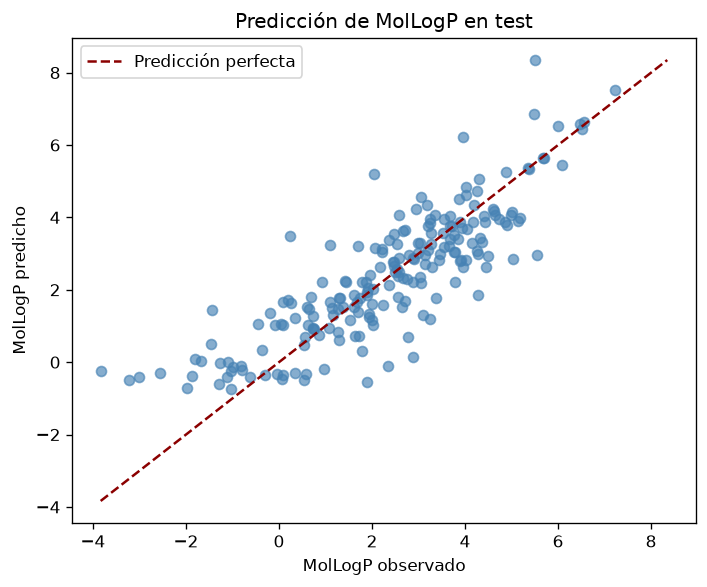

In [4]:
# Importo métricas para comparar el ajuste dentro y fuera de la muestra.
from sklearn.metrics import mean_squared_error, r2_score  # Calculo R cuadrado y errores.
import matplotlib.pyplot as plt  # Dibujo una sola figura de evaluación.

# Predigo MolLogP en train y test con el mismo modelo.
pred_train = modelo.predict(add_constant(X_train, has_constant='add'))  # Predigo los datos de entrenamiento.
pred_test = modelo.predict(add_constant(X_test, has_constant='add'))  # Predigo los datos reservados.

# Calculo las métricas en las dos particiones.
metricas_train = {'R²': r2_score(y_train, pred_train), 'MSE': mean_squared_error(y_train, pred_train), 'RMSE': np.sqrt(mean_squared_error(y_train, pred_train))}  # Resumo train.
metricas_test = {'R²': r2_score(y_test, pred_test), 'MSE': mean_squared_error(y_test, pred_test), 'RMSE': np.sqrt(mean_squared_error(y_test, pred_test))}  # Resumo test.
comparacion = pd.DataFrame({'train': metricas_train, 'test': metricas_test})  # Comparo las métricas.
comparacion['diferencia test-train'] = comparacion['test'] - comparacion['train']  # Calculo la brecha entre particiones.
display(comparacion.round(3))  # Muestro el rendimiento comparado.
r2_ajustado_train = 1 - (1 - metricas_train['R²']) * (len(y_train) - 1) / (len(y_train) - X_train.shape[1] - 1)  # Calculo R² ajustado en train.
print(f"R² ajustado de train = {r2_ajustado_train:.3f}; diferencia R² test-train = {metricas_test['R²'] - metricas_train['R²']:+.3f}.")  # Interpreto la brecha.
print(f"Diferencia RMSE test-train = {metricas_test['RMSE'] - metricas_train['RMSE']:+.3f}; un valor positivo indica más error en test.")  # Interpreto el error externo.

# Comparo observado y predicho en test con una línea de predicción perfecta.
fig, ax = plt.subplots(figsize=(6, 5))  # Creo una figura compacta.
ax.scatter(y_test, pred_test, alpha=0.65, color='steelblue')  # Dibujo cada observación reservada.
limites = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]  # Calculo el rango común.
ax.plot(limites, limites, color='darkred', linestyle='--', label='Predicción perfecta')  # Marco la referencia y=x.
ax.set_xlabel('MolLogP observado')  # Etiqueto el eje horizontal.
ax.set_ylabel('MolLogP predicho')  # Etiqueto el eje vertical.
ax.set_title('Predicción de MolLogP en test')  # Titulo la comparación.
ax.legend()  # Muestro la referencia.
plt.tight_layout()  # Ajusto la figura.
plt.show()  # Presento la evaluación visual.


## Lectura del modelo

El VIF reduce predictores redundantes antes del ajuste. En la tabla de coeficientes, el signo indica la dirección de la asociación con MolLogP y el valor p describe la evidencia dentro de train; no es una relación causal. La tabla train-test muestra si el ajuste mantiene su rendimiento en compuestos reservados. Interpreto el R² ajustado en train y comparo el R² y RMSE entre particiones.
